# Import modules

In [1]:
import pandas as pd #used to load the csv files, manipulate and process data, etc.. (library used for data science)
import os #used to do deal with the operating system, eg input, output, save files, etc.. (Mac in this  case)
import multiprocessing as mp #used to used more than one thread of the CPU for performance and time effciency 
from functools import partial # same as above
from joblib import Parallel, delayed # same as above 
from concurrent.futures import ThreadPoolExecutor # same as above
from typing import List, Tuple, Dict # Python is a *not typed language*, meaning it understands basic units. used to classfy input variables (e.g a:List=[])
import pickle 
import networkx as nx # used to visualize nodes and edges
import matplotlib.pyplot as plt #visualisation library (e.g charts, plots, pie chart, etc.)
import seaborn as sns # same as above(more features)
import numpy as np # library used for linear algebra (e.g matrices) (used to define the adjacency matrix below)
import itertools
import time
from numba import jit, cuda
from concurrent.futures import ProcessPoolExecutor, as_completed
from joblib import Parallel, delayed
from multiprocessing import Lock
import numpy as np
import pandas as pd
import itertools
import networkx as nx
import ray
import psutil
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.ensemble import GradientBoostingClassifier
from typing import Set, List, Tuple, Dict
from ipycytoscape import CytoscapeWidget
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Classes
- Class to store data about the bond

In [2]:
class Bond: #this class is used to store bond data seperately, each instance of the class represnts one bond
    id_number: str #string is the text
    bond_row: pd.Series  # this is the 'row' of  one bond - pd.Series means 'one single row' (this is for the Sustainable Debt Excel sheet)
    holders: pd.DataFrame # list of holders - the pd.DataFrame is the Pandas Library. DataFrame means 'table'- 'more than one row'. (this is for the holders excel for each bond, as represented in a table)
    def __init__(self, id_number:str, bond_row: pd.Series, holders: pd.DataFrame): # intiation of class ( Arguments: 1) Id number, then Bond data, then Holders) 
        self.id_number = id_number # 'self' is refering to the instance of the class (id number of class=id number)
        self.bond_row = bond_row
        self.holders = holders

    # make the class compatable with set()
    def __hash__(self): #this is used
        return hash(self.id_number)
    
    def __eq__(self, other): #this is used to compare two instances of the class
        return self.id_number == other.id_number
    
    def __repr__(self): #this is used to print the instance of the class
        return self.id_number
    
    def __str__(self): #this is used to print the instance of the class
        return self.id_number

class HolderInfo:
    holder_index: int
    holder_name: str
    bonds: Set[Bond]
    collaborators: Set[str]
    bonds_in_Asia: Set[Bond]
    bonds_in_Europe: Set[Bond]
    bonds_in_North_America: Set[Bond]
    bonds_in_South_America: Set[Bond]
    bonds_in_Africa: Set[Bond]
    bonds_in_Oceania: Set[Bond]
    bonds_in_Other: Set[Bond]
    bonds_as_Green_Theme: Set[Bond]
    bonds_as_Social_Theme: Set[Bond]
    bonds_as_Sustainability_Theme: Set[Bond]
    
    def __init__(self, holder_index: int, holder_name: str):
        self.holder_index = holder_index
        self.holder_name = holder_name
        self.bonds = set()
        self.collaborators = set()
        self.bonds_in_Asia = set()
        self.bonds_in_Europe = set()
        self.bonds_in_North_America = set()
        self.bonds_in_South_America = set()
        self.bonds_in_Africa = set()
        self.bonds_in_Oceania = set()
        self.bonds_in_Other = set()
        self.bonds_as_Green_Theme = set()
        self.bonds_as_Social_Theme = set()
        self.bonds_as_Sustainability_Theme = set()

    # make the class compatable with set()
    def __hash__(self):
        return hash(self.holder_index)
    
    def __eq__(self, other):
        return self.holder_index == other.holder_index
    
    def __repr__(self):
        return self.holder_name
    
    def __str__(self):
        return self.holder_name
    
    def to_dict(self):
        return {
            "holder_index": self.holder_index,
            "holder_name": self.holder_name,
            "bonds": [bond.id_number for bond in self.bonds],
            "collaborators": self.collaborators,
            "bonds_in_Asia": [bond.id_number for bond in self.bonds_in_Asia],
            "bonds_in_Europe": [bond.id_number for bond in self.bonds_in_Europe],
            "bonds_in_North_America": [bond.id_number for bond in self.bonds_in_North_America],
            "bonds_in_South_America": [bond.id_number for bond in self.bonds_in_South_America],
            "bonds_in_Africa": [bond.id_number for bond in self.bonds_in_Africa],
            "bonds_in_Oceania": [bond.id_number for bond in self.bonds_in_Oceania],
            "bonds_in_Other": [bond.id_number for bond in self.bonds_in_Other],
            "bonds_as_Green_Theme": [bond.id_number for bond in self.bonds_as_Green_Theme],
            "bonds_as_Social_Theme": [bond.id_number for bond in self.bonds_as_Social_Theme],
            "bonds_as_Sustainability_Theme": [bond.id_number for bond in self.bonds_as_Sustainability_Theme]
        }

# Data Processing and Cleaning
- Defining the functions to process the data and clean it.

In [3]:
holders_columns = [ #here, we added a new coloumn called "ID Type" since in the original sheet, ID CORP was together, as shown in the Holders-columns.png, and i thought that putting this info in a spereate column is better
    "ID number",
    "ID Type",
    "Holder Name",
    "Porfolio Name",
    "Parent Holder Id",
    "Holder Id",
    "Portfolio Number",
    "Position",
    "Position Change",
    "Filling Date",
    "Filling Source",
    "Insider Status",
    "Percent Outstanding",
    "Percent of Portfolio",
    "Institution Type",
    "Metro Area",
    "Country",
    "File Name" # we put this is order to located the csv file of the holder
]

def read_holder_file(file_path: str) -> pd.DataFrame: # function(input)=output....takes input of the file location. This reads one csv holder file
    # Initialize an empty list to store rows 
    rows = []
    
    with open(file_path, 'r', encoding='utf-8') as file: # open file ('r' means read) and i named it (file)
        for line in file: # used to go through each line in our file.
            try:
                # Split the line by comma since the data is comma seperatied (e.g'x,c,v,b,n..') we convert it to a list: [x,c,v]
                fields = line.strip().split(',')
                # remove quotation marks from each field because some of the holders name had a quotation mark, and this can cause ineffeciencies in collecting the data
                fields = [field.strip('"') for field in fields]
                #this below was used to re arrange the rows and columns, seperating the Id number and Id type
                [id_number, bond_type] = fields[0].split(' ') # split by (space bar) because it was (B1234 Corp) and we want to seperate them. Since they are initially seperated by a space, we used this function. And we named the  (id number) (id type)
                fields.insert(0, id_number) #put the new field that were done above (before column 0, we put Id_Number- so now ID number is column 0)
                fields[1] = bond_type # here we take column one and make it the (bond type)
                #this is used to fix the issue where so of the rows in the bond holders list was shifted to the right
                if len(fields) != len(holders_columns)-1: #(-1 is because we added a new column called 'File name' as seen above, but we did not add it yet)
                    fields[2] = fields[2] + ',' + fields[3] #some companies have their name as 'ABC,CO' (They are seperated by a comma), therefore, this line fixes this issue because without it, it would assume that they are two separate columns 
                    fields.pop(3) #removes item 3
                
                fields.append(file_path) #here we added the file name column. 
                
                rows.append(fields)# Add items to the fields to the list of rows to store the items in a table
            except Exception as e:
                print(f"Skipping row with error: {e}")
                continue
    
    # Create DataFrame from the list of rows with column names
    df = pd.DataFrame(rows, columns=holders_columns)

    return df

def read_all_holders(directory_name: str) -> pd.DataFrame:
    def process_file(filename: str) -> pd.DataFrame:
        file_path = os.path.join(directory_name, filename)
        return read_holder_file(file_path)

    filenames = [f for f in os.listdir(directory_name) if f.endswith('.csv')]

    with ThreadPoolExecutor() as executor:
        # Map the process_file function to the list of filenames
        results = list(executor.map(process_file, filenames))
    
    # Concatenate all dataframes into one
    return pd.concat(results, ignore_index=True)


def read_bonds(file_path: str, holders_directory: str) -> set[Bond]: # calls the function above (hodlers) with the bond names from the Sustainable Debt Excel
    bond_table = pd.read_csv(file_path) #read the csv with pandas
    holders = read_all_holders(holders_directory) #we created our own function and did not used pandas because the holders list had issues
    # Merge dataframes based on 'ID number'
    merged_data = bond_table.merge(holders, on='ID number', how='inner')
    # Group the merged data by "ID number"
    grouped_data = merged_data.groupby("ID number")
    result = set()
    for id_number, group in grouped_data:
        bond_row = group.iloc[0, :len(bond_table.columns)] 
        holders_df = group.iloc[:, len(bond_table.columns):] 
        bond = Bond(id_number, bond_row, holders_df) # we are adding the bonds with their holders
        result.add(bond)
    return result

# Loading Data Set
- Load the files and clean the data 

In [4]:
bond_list = read_bonds('all-bonds.csv', 'holders/') # list of classes 'Bond'
total_bonds = len(bond_list)

unique_holders = set()
bond_type_dict: Dict[str, List[Bond]] = {}
bond_theme_dict: Dict[str, List[Bond]] = {}
issuer_industry_dict: Dict[str, List[Bond]] = {}
issuer_currency_dict: Dict[str, List[Bond]] = {}
sub_industry_dict: Dict[str, List[Bond]] = {}
bonds_with_single_holder = []

for bond in bond_list:
    holders = bond.holders['Holder Name']

    # push holders to unique holders set
    for holder in holders:
        unique_holders.add(holder)
    
    # Handle bond type dictionary
    bond_type = bond.bond_row['Bond type']

    if bond_type not in bond_type_dict:
        bond_type_dict[bond_type] = []
    bond_type_dict[bond_type].append(bond)

    # Handle issuer industry dictionary
    issuer_industry = bond.bond_row['Issuer industry']
    if issuer_industry not in issuer_industry_dict:
        issuer_industry_dict[issuer_industry] = []
    issuer_industry_dict[issuer_industry].append(bond)

    # Handle issuer currency dictionary
    issuer_currency = bond.bond_row['Issue currency']
    if issuer_currency not in issuer_currency_dict:
        issuer_currency_dict[issuer_currency] = []
    issuer_currency_dict[issuer_currency].append(bond)

    # Handle bond theme dictionary
    bond_theme = bond.bond_row['Theme']
    if bond_theme == 'Sustainability-linked':
        print(bond.bond_row)

    if bond_theme not in bond_theme_dict:
        bond_theme_dict[bond_theme] = []
    bond_theme_dict[bond_theme].append(bond)

    # Handle sub industry dictionary
    sub_industry = bond.bond_row['Issuer sub-industry']
    if sub_industry not in sub_industry_dict:
        sub_industry_dict[sub_industry] = []
    sub_industry_dict[sub_industry].append(bond)

    if len(holders) == 1:
        bonds_with_single_holder.append(bond)

holder_to_index = {holder: i for i, holder in enumerate(unique_holders)}
index_to_holder = {i: holder for i, holder in enumerate(unique_holders)}
bond_types = list(bond_type_dict.keys())
num_bond_types = len(bond_types)
num_unique_holders = len(unique_holders)
print(f"Total number of bonds: {total_bonds}")
print(f"Total number of unique holders: {num_unique_holders}")
print(f"Total number of unique bond types: {num_bond_types}")
print(f"Total number of unique issuer industries: {len(issuer_industry_dict)}")
print(f"Total number of unique issuer currencies: {len(issuer_currency_dict)}")
print(f"Total number of unique bond themes: {len(bond_theme_dict)}")
print(f"Total number of unique sub industries: {len(sub_industry_dict)}")
print(f"Bond themes are: {list(bond_theme_dict.keys())}")
print(f"Currencies are: {list(issuer_currency_dict.keys())}")
print(f"Bonds with single holder: {len(bonds_with_single_holder)}")

Total number of bonds: 2495
Total number of unique holders: 3126
Total number of unique bond types: 6
Total number of unique issuer industries: 11
Total number of unique issuer currencies: 35
Total number of unique bond themes: 3
Total number of unique sub industries: 61
Bond themes are: ['Social', 'Green', 'Sustainability']
Currencies are: ['JPY', 'EUR', 'USD', 'MYR', 'KRW', 'AUD', 'GBP', 'CAD', 'SEK', 'MXN', 'NOK', 'NZD', 'ZAR', 'CNY', 'SGD', 'BRL', 'THB', 'CHF', 'PEN', 'HKD', 'CLP', 'IDR', 'INR', 'ARS', 'KZT', 'PHP', 'PLN', 'UYU', 'TRY', 'EGP', 'COP', 'UZS', 'RUB', 'DKK', 'NAD']
Bonds with single holder: 354


In [6]:
# New dictionary to group currencies by region
region_currency_dict: Dict[str, List[Bond]] = {
    "North America": [],
    "South America": [],
    "Europe": [],
    "Asia": [],
    "Oceania": [],
    "Africa": []
}

# Define the regions for each currency
currency_regions = {
    "USD": "North America", "CAD": "North America", "MXN": "North America",
    "CLP": "South America", "PEN": "South America", "BRL": "South America",
    "ARS": "South America", "COP": "South America", "UYU": "South America",
    "EUR": "Europe", "RUB": "Europe", "GBP": "Europe", "SEK": "Europe",
    "NOK": "Europe", "CHF": "Europe", "PLN": "Europe", "TRY": "Europe",
    "DKK": "Europe",
    "KRW": "Asia", "JPY": "Asia", "INR": "Asia", "THB": "Asia", "MYR": "Asia",
    "CNY": "Asia", "SGD": "Asia", "IDR": "Asia", "HKD": "Asia", "PHP": "Asia",
    "UZS": "Asia", "KZT": "Asia",
    "AUD": "Oceania", "NZD": "Oceania",
    "ZAR": "Africa", "EGP": "Africa", "NAD": "Africa"
}

for currency, bonds in issuer_currency_dict.items():
    region = currency_regions.get(currency, "Other")
    if region != "Other":
        region_currency_dict[region].extend(bonds)

# print first 5 bonds in each region
for region, bonds in region_currency_dict.items():
    print(f"Region: {region} has {len(bonds)} bonds")

Region: North America has 988 bonds
Region: South America has 41 bonds
Region: Europe has 1002 bonds
Region: Asia has 376 bonds
Region: Oceania has 77 bonds
Region: Africa has 11 bonds


# Extract Data set information
- Visualize the type of bonds in the data set

In [17]:
%matplotlib qt
# visualize region_currency_dict as a bar chart 
region_currency_counts = {region: len(currencies) for region, currencies in region_currency_dict.items()}
plt.barh(region_currency_counts.keys(), region_currency_counts.values())
plt.ylabel("Region")
plt.xlabel("Number of Bonds")
plt.title("Number of Bonds per Region")
plt.show()

In [18]:
%matplotlib qt
# visualize the bond themes as a pie chart
theme_counts = {theme: len(bonds) for theme, bonds in bond_theme_dict.items()}
# # change the default color cycle
# plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.blue)
# plt.pie(theme_counts.values(), labels=theme_counts.keys(), autopct='%1.1f%%')

# only "explode" the 2nd slice (i.e. 'Hogs')
explode = (0.001, 0.001, 0.001)

#colors
colors = ['#ff9999','#66b3ff','#99ff99']
#explsion
 
plt.pie(theme_counts.values(), colors = colors, labels=theme_counts.keys(), autopct='%1.1f%%', startangle=90, pctdistance=0.85, explode = explode)
#draw circle
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
ax = fig.gca()
fig.gca().add_artist(centre_circle)
# Equal aspect ratio ensures that pie is drawn as a circle
ax.axis('equal')  
plt.title("Percenatge of Bonds per Theme")
plt.tight_layout()
plt.show()

In [19]:
%matplotlib qt
# visualize the bond types as a horizontal bar chart
bond_type_counts = {bond_type: len(bonds) for bond_type, bonds in bond_type_dict.items()}
plt.barh(list(bond_type_counts.keys()), bond_type_counts.values())
plt.xlabel("Number of Bonds")
plt.ylabel("Bond Type")
plt.title("Number of Bonds per Type")
plt.show()

In [20]:
%matplotlib qt
# visualize the issuer industries as a horizontal bar chart
issuer_industry_counts = {industry: len(bonds) for industry, bonds in issuer_industry_dict.items()}
plt.barh(list(issuer_industry_counts.keys()), issuer_industry_counts.values())
plt.xlabel("Number of Bonds")
plt.ylabel("Issuer Industry")
plt.title("Number of Bonds per Issuer Industry")
plt.show()

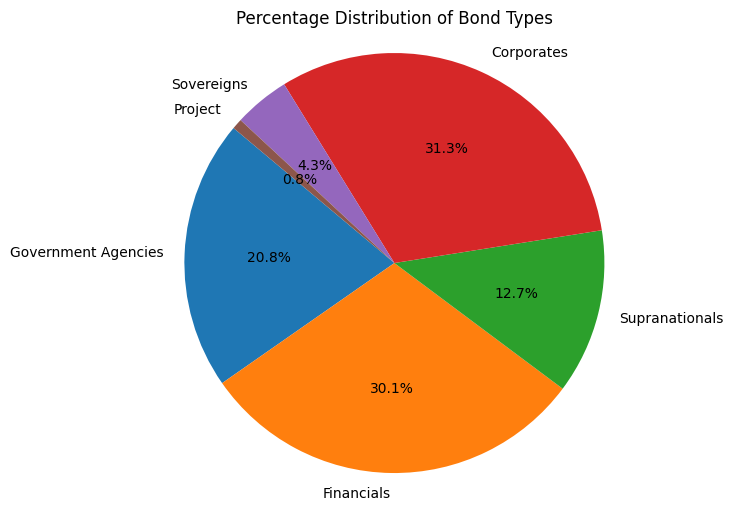

In [232]:
%matplotlib inline
# Create a dictionary to count bonds of each type
bond_type_counts = {bond_type: len(bonds) for bond_type, bonds in bond_type_dict.items()}

# Calculate percentage distribution of bond types
bond_type_percentages = {bond_type: (count / total_bonds) * 100 for bond_type, count in bond_type_counts.items()}
plt.figure(figsize=(8, 6))
plt.pie(bond_type_percentages.values(), labels=bond_type_percentages.keys(), autopct='%1.1f%%', startangle=140)
plt.title('Percentage Distribution of Bond Types')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

- Visualize the issuer industry distribution

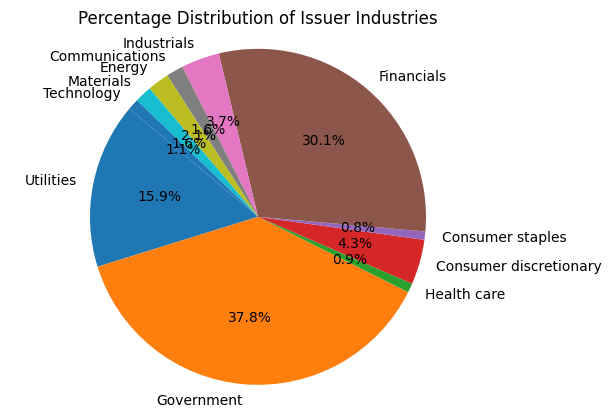

In [37]:
# Create a dictionary to count bonds of each type
issuer_industry_counts = {issuer_type: len(bonds) for issuer_type, bonds in issuer_industry_dict.items()}

# Calculate percentage distribution of bond types
issuer_industry_percentages = {issuer_industry: (count / total_bonds) * 100 for issuer_industry, count in issuer_industry_counts.items()}
plt.pie(issuer_industry_percentages.values(), labels=issuer_industry_percentages.keys(), autopct='%1.1f%%', startangle=140)
plt.title('Percentage Distribution of Issuer Industries')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

- Visualize bonds and how many holders they have

# Generating Adjacency Matrix 

In [7]:
# we want to present the data as a graph network using an adjacency matrix
# so basically the unique_holders will represent the nodes of the graph
# when two unique holders are present in the same bond, this indicates an edge meaning we will increment the value of the adjacency matrix at the corresponding index of the two holders
# we will use a dictionary to map the holder name to an index in the adjacency matrix
# Create a defaultdict to collect pairs of indices to be incremented
def create_adjacency_matrix(bond_list, holder_to_index, index_to_holder):
    num_unique_holders = len(holder_to_index)
    adjacency_matrix = np.zeros((num_unique_holders, num_unique_holders), dtype=np.int32)
    # holder name, [number of collaborations, bonds, collaborators]
    # holder index: {holder_name, number of collaborations, bonds, collaborators, bonds in Asia, bonds in Europe, bonds in North America, bonds in South America, bonds in Africa, bonds in Oceania, bonds in Other, bonds as Green Theme, bonds as Social Theme, bonds as Sustainability Theme}
    holder_info: Dict[int, HolderInfo] = {}
    for bond in bond_list:
        holders = bond.holders['Holder Name']
        indices = np.unique([holder_to_index[holder] for holder in holders])

        for index in indices:
            holder = index_to_holder[index]
            if index not in holder_info:
                holder_info[index] = HolderInfo(index, holder)
            holder_info[index].bonds.add(bond)
            collaborators = [index_to_holder[i] for i in indices if i != index]
            holder_info[index].collaborators.update(collaborators)
            if bond.bond_row['Issue currency'] in currency_regions:
                region = currency_regions[bond.bond_row['Issue currency']]
                if region == 'Asia':
                    holder_info[index].bonds_in_Asia.add(bond)
                elif region == 'Europe':
                    holder_info[index].bonds_in_Europe.add(bond)
                elif region == 'North America':
                    holder_info[index].bonds_in_North_America.add(bond)
                elif region == 'South America':
                    holder_info[index].bonds_in_South_America.add(bond)
                elif region == 'Africa':
                    holder_info[index].bonds_in_Africa.add(bond)
                elif region == 'Oceania':
                    holder_info[index].bonds_in_Oceania.add(bond)
                else:
                    holder_info[index].bonds_in_Other.add(bond)
            if bond.bond_row['Theme'] == 'Green':
                holder_info[index].bonds_as_Green_Theme.add(bond)
            elif bond.bond_row['Theme'] == 'Social':
                holder_info[index].bonds_as_Social_Theme.add(bond)
            elif bond.bond_row['Theme'] == 'Sustainability':
                holder_info[index].bonds_as_Sustainability_Theme.add(bond)
        
        # adjacency matrix
        i, j = np.meshgrid(indices, indices, indexing='ij')

        # Filter out the diagonal elements (self-connections)
        mask = i != j

        # Update the adjacency matrix with the count of connections
        adjacency_matrix[i[mask], j[mask]] += 1

    # create a pandas dataframe to store the holder information
    

    data = [holder.to_dict() for holder in holder_info.values()]
    holder_df = pd.DataFrame(data)

    # Make the adjacency matrix symmetric
    # adjacency_matrix += adjacency_matrix.T

    return adjacency_matrix, holder_df, holder_info

# print me the two holders with the highest number of collaborations and their names 
def print_top_collaborations(adjacency_matrix, unique_holders, holder_info):
    # Get the indices of the top 2 holders with the highest number of collaborations
    i, j = np.unravel_index(np.argsort(adjacency_matrix, axis=None), adjacency_matrix.shape)
    # Get the holder names corresponding to the indices
    holder_names = np.array(list(unique_holders))
    holder_i = holder_names[i[-1]]
    holder_j = holder_names[j[-1]]
    # Get the number of collaborations
    collaborations = adjacency_matrix[i[-1], j[-1]]
    print(f"Top 2 holders with the highest number of collaborations:\n{holder_i} and {holder_j} with {collaborations} collaborations")
    holder_i_info = holder_info[i[-1]]
    holder_j_info = holder_info[j[-1]]
    print(f"Holder i: {holder_i_info} with index {i[-1]} and Holder j: {holder_j_info} with index {j[-1]}")

adjacency_matrix, holders_df, holder_info = create_adjacency_matrix(bond_list, holder_to_index, index_to_holder)
G = nx.from_numpy_array(adjacency_matrix, create_using=nx.Graph())
print_top_collaborations(adjacency_matrix, unique_holders, holder_info)


print(adjacency_matrix[0:20, 0:20]) # TODO: prints the first 20 rows and columns of the adjacency matrix 

# sort the holders with the highest number of collaborations
# holders_df = holders_df.sort_values(by='Collaborations', ascending=False)

# sort holders df by number of bonds, bonds is a list so i want you to get the number of elements and sort by that
holders_df.head(20) # TODO: prints the top 20 holders with the highest number of collaborations

Top 2 holders with the highest number of collaborations:
BlackRock Inc and Vanguard Group Inc/The with 1214 collaborations
Holder i: BlackRock Inc with index 2750 and Holder j: Vanguard Group Inc/The with index 507
[[ 0  1  0  0  2  4  2  0 20  0 34  0  1  0  3  3  2  1 23  3]
 [ 1  0  0  0  0  1  0  0  1  0  0  0  0  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0]
 [ 4  1  0  0  0  0  0  0  5  0  1  0  0  0  1  0  1  0  5  0]
 [ 2  0  0  0  0  0  0  0  1  0  1  0  0  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [20  1  0  0  0  5  1  0  0  0  7  0  1  0  1  1  0  0 13  1]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [34  0  0  0  0  1  1  0  7  0  0  0  0  0  0  5  0  0  7  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  1 

,holder_index,holder_name,bonds,collaborators,bonds_in_Asia,bonds_in_Europe,bonds_in_North_America,bonds_in_South_America,bonds_in_Africa,bonds_in_Oceania,bonds_in_Other,bonds_as_Green_Theme,bonds_as_Social_Theme,bonds_as_Sustainability_Theme
0,1431,Government Pension Investment Fund,"[BS8678234, BN3334347, BV7193659, BQ3470789, 7...","{Legal & General Group PLC, Commerce West Insu...","[BS8678234, ZO4480315, BM4074019, BO8404416, B...","[BN3334347, BV7193659, ZN7989223, BJ7356899, B...","[BK2308355, 74432QCH6, 75972AAD5, 11271LAJ1, 4...","[BZ8640485, BQ3398386]",[],"[BT3055907, AW5321707, ZS1061341, ZM2251969, B...",[],"[BN3334347, BV7193659, 74432QCH6, 11271LAJ1, B...","[BS8678234, BV4086062, BO7671841, BO7141944, B...","[ZO4480315, BN4540991, BT3055907, BM4074019, B..."
1,1155,Allianz SE,"[UV9948976, BT4313446, ZQ8043205, BM5819818, B...","{Legal & General Group PLC, Commerce West Insu...","[AM7323968, BS1852240, BY2664054, BK8156469, B...","[UV9948976, BT4313446, ZQ8043205, BM5819818, B...","[744448CQ2, 74432QCH6, 11271LAJ1, 85859NAA0, 8...","[BM6607360, BZ8640485, BM6609572, BQ3398386]",[BT4847468],"[AV6924899, ZM2251969, BN2964045, ZO5649603, Z...",[],"[UV9948976, BT4313446, ZQ8043205, BM5819818, B...","[BV4086062, BQ2145937, BO7671841, BO7141944, Z...","[BN4540991, AS3626619, 459058KA0, 01609WAY8, 5..."
2,117,New York Life Insurance Co,"[98105EAM9, 744448CQ2, 45434L2H6, 892331AN9, 6...","{Legal & General Group PLC, Commerce West Insu...",[],"[ZN3745520, BW7932815]","[98105EAM9, 744448CQ2, 45434L2H6, 892331AN9, 6...",[],[],[],[],"[744448CQ2, 45434L2H6, 665772CR8, 37045VAY6, 5...","[401494AS8, 34531XAB0, 168863DU9, 682691AB6, 1...","[98105EAM9, 66765RCK0, 200447AL4, 637432NZ4, 8..."
3,246,United Services Automobile Associa,"[98105EAM9, 62954HBB3, 29444UBL9, 65339KBW9, 2...","{Legal & General Group PLC, Federated Hermes I...",[],[],"[98105EAM9, 62954HBB3, 29444UBL9, 65339KBW9, 2...",[],[],[],[],"[62954HBB3, 29444UBL9, 65339KBW9, 23338VAR7, 9...","[75936LAC8, 75936LAB0, 78081BAN3, 168863DT2, 8...","[168863DW5, 98105EAM9, 10806CAA6, 892331AM1, 2..."
4,251,Liberty Bankers Life Insurance Co,"[98105EAM9, 62954HBB3, 151191BJ1, 78392BAF4, 6...","{Catholic Life Insurance Union, Federated Herm...",[],[],"[98105EAM9, 62954HBB3, 151191BJ1, 78392BAF4, 6...",[],[],[],[],"[78392BAF4, 62582PAA8, 62954HBB3]",[],"[151191BJ1, 98105EAM9]"
5,306,Nationwide Life Insurance Co,"[29444UBU9, 11272BAA1, 98105EAM9, 11271LAH5, 8...","{Federated Hermes Inc, Legal & General Group P...",[],[],"[29444UBU9, 11272BAA1, 98105EAM9, 11271LAH5, 8...",[],[],[],[],"[29444UBU9, 11272BAA1, 11271LAH5, 89054XAB1, 4...",[],"[26442CBG8, 168863DW5, 98105EAM9, 63307A2M6, 9..."
6,507,Vanguard Group Inc/The,"[BM5819818, BN3334347, 98105EAM9, 744448CQ2, 7...","{Legal & General Group PLC, Commerce West Insu...","[BR3159463, ZR1181208, AZ0174443, BY9989892, B...","[BT4313446, ZQ8043205, BM5819818, BN3334347, B...","[98105EAM9, 744448CQ2, 20752XAA3, BS1372157, 7...","[BS9593523, BZ8640485, BQ3398386]",[],"[BT3055907, AW5321707, AV3246445, ZS1061341, Z...",[],"[BT4313446, ZQ8043205, BM5819818, BN3334347, 7...","[12802D2H8, BV4086062, BQ2145937, BW1683943, B...","[98105EAM9, ZQ6650134, BZ5062956, ZM2000879, 8..."
7,707,HCSC Insurance Services Co,"[98105EAM9, 843646AW0, 48305QAF0, 037833CX6, 1...","{Legal & General Group PLC, Marketfield Asset ...",[],[],"[98105EAM9, 843646AW0, 48305QAF0, 037833CX6, 1...",[],[],[],[],"[929043AL1, 345370DA5, 44107TBA3, 62954HBB3, 3...","[168863DU9, 05959LAH6, 168863DT2]","[26442CBG8, 50050GAN8, BT4882697, 98105EAM9, 2..."
8,847,Shelter Mutual Insurance Co,"[85571BAW5, 98105EAM9, 34531XAB0, 345370DA5, 4...","{Legal & General Group PLC, Federated Hermes I...",[],[],"[85571BAW5, 98105EAM9, 34531XAB0, 345370DA5, 4...",[],[],[],[],"[345370DA5, 345370DB3, 30251GBE6, 44107TAZ9]",[34531XAB0],"[855244AK5, 85571BAW5, 98105EAM9, 48723RAC9]"
9,1067,Nationwide Life and Annuity Insura,"[29444UBU9, 11272BAA1, 98105EAM9, 373334KE0, 8...","{Federated Hermes Inc, 

# Visualizing adjacency matrix as heatmap

In [116]:
%matplotlib qt
import seaborn as sns
import matplotlib.pylab as plt
sorted_nodes = list(np.random.choice(G.nodes(), 35, replace=False) )
# convert it to numpy array
adjacency_matrix_2 = nx.to_numpy_array(G, nodelist=sorted_nodes)

ax = sns.heatmap(adjacency_matrix_2[0:35, 0:35], linewidth=0.5, cmap='crest', vmin=0, vmax=10, cbar_kws={'label': '# of Collaborations', 'pad': 0.01})
# Add a title
plt.title('Adjacency Matrix (First 35 Holders)')
plt.ylabel('Holder Index')
plt.xlabel('Holder Index')
ax.invert_yaxis()
plt.show()

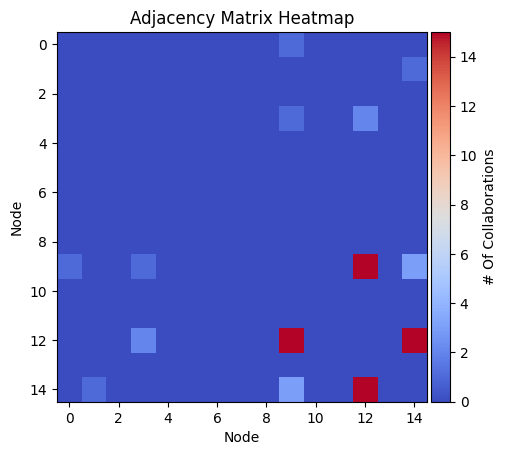

In [18]:
# only select part of adjacency matrix that is non zero to make the plot more readable

cax = plt.imshow(adjacency_matrix[0:15, 0:15], cmap='coolwarm', vmin=0, vmax=15) # TODO: visuaize the adjacency matrix with the first 15 rows and columns, (vmax is max number of collaborations to show)

# Adding color bar
cb = plt.colorbar(fraction=0.046, pad=0.01)
cb.set_label('# Of Collaborations')  # Set the color bar title font size

# Adding labels
plt.title('Adjacency Matrix Heatmap')
plt.xlabel('Node')
plt.ylabel('Node')


plt.show()

# Visualizing adjacency matrix as network
- First block of code extracts 10 nodes (holders) that are all interconnected with one another with a minimum of 2 connections each

In [11]:
# 1098, 25, 2622, 1229, 1769, 2762, 2728, 1795, 2043, 2299, 2969, 1316, 2705, 2452, 1240, 2457, 811, 568, 2136, 474, 51, 3124, 1840, 2057, 127, 2915, 2120, 2675, 2918, 1344
# Function to find 10 nodes each having at least 2 connections within the subset
def find_suitable_nodes(G, num_nodes=10, min_connections=2):

    # # return random subset of nodes, so randomly select num_nodes nodes
    # nodes = list(np.random.choice(G.nodes(), num_nodes, replace=False) )
    # # remove nodes with less than min_connections
    # for node in nodes:
    #     if G.degree(node) < min_connections:
    #         nodes.remove(node)
    # return nodes


    # Start with nodes sorted by degree (descending)
    sorted_nodes = sorted(G.nodes(), key=lambda n: G.degree(n), reverse=True)

    # return sorted_nodes[1000:num_nodes+1000]
    # return sorted_nodes[0:num_nodes]

    # return last num_nodes nodes
    # return sorted_nodes[-num_nodes:]


    for start_node in sorted_nodes:
        # Begin with the highest-degree node and attempt to build a suitable subset
        sub_nodes = [start_node]
        for node in sorted_nodes:
            if node not in sub_nodes and all(G.degree(n) >= min_connections for n in sub_nodes):
                sub_nodes.append(node)
            if len(sub_nodes) == num_nodes:
                break
        
        subgraph = G.subgraph(sub_nodes)
        if len(subgraph) == num_nodes and all(subgraph.degree(n) >= min_connections for n in sub_nodes):
            return sub_nodes

    return None

# Find 10 suitable nodes
suitable_nodes = find_suitable_nodes(G, num_nodes=10, min_connections=1) # TODO: extracts 10 nodes to visualize in the following block of code

print(f"Suitable nodes: {suitable_nodes}")

Suitable nodes: [2750, 2484, 2728, 1942, 905, 1155, 507, 231, 2256, 1977]


In [38]:
%matplotlib qt
# 1. random 30 nodes
# 2. top collaborators 
# 3. newest 10 and oldest 10 nodes 
# 4. US region vs Asia region 
# 5. Green vs Social vs Sustainability
# 6. Visualize bond with the highest number of collaborations
# 7. Visualize top 10 bonds with the highest number of collaborations
def get_graph(G, suitable_nodes, node_colors):
    subgraph = G.subgraph(suitable_nodes)
    # Get node positions
    pos = nx.spring_layout(subgraph)

    number_of_nodes = len(suitable_nodes)
    
    node_colors = {}
    node_colors_hex = {}
    node_color_map = plt.get_cmap('Blues')

    for i in range(number_of_nodes):
        node = suitable_nodes[i]
        color = node_color_map(i / number_of_nodes)
        node_colors[node] = color
        node_colors_hex[node] = mcolors.to_hex(color)
    
    return subgraph, pos, node_colors,  node_colors_hex 

def plot_interactive(G, suitable_nodes, subgraph, pos, node_colors):
    # subgraph = G.subgraph(suitable_nodes)
    # Get node positions
    # pos = nx.spring_layout(subgraph)


    # degrees = dict(subgraph.degree())

    # Normalize degrees
    # degree_values = list(degrees.values())
    # min_degree = min(degree_values)
    # max_degree = max(degree_values)

    # if max_degree == min_degree:
    #     normalized_degrees = {node: 0.5 for node in degrees}  # All nodes have the same degree
    # else:
    #     normalized_degrees = {node: (degrees[node] - min_degree) / (max_degree - min_degree) for node in degrees}


    # Create the Cytoscape widget
    cytoscape_widget = CytoscapeWidget()
    cytoscape_widget.graph.add_graph_from_networkx(subgraph)

    # Update style for nodes and edges
    style = [
        {
            'selector': 'node',
            'style': {
                'label': 'data(id)',
                'text-valign': 'center',
                'text-halign': 'center',
                'width': '30px',  # Increase node size
                'height': '30px',  # Increase node size
                'background-color': 'data(color)',  # Use data-mapped color
                'font-size': '12px',
                'color': '#000000',
                'text-wrap': 'wrap'
            }
        },
        {
            'selector': 'edge',
            'style': {
                'label': 'data(weight)',
                'opacity': 0.7,
                'curve-style': 'bezier',
                'control-point-step-size': 40,
                'font-size': '11px',
                'text-background-color': '#6FB1FC',
                'text-background-opacity': 1,
                'text-background-padding': '2px'
            }
        },
        {
            'selector': 'edge[weight <= 1]',
            'style': {
                'label': ''  # Hide label for edges with weight <= 1
            }
        }
    ]

    # # Assign colors to nodes in Cytoscape widget
    for node in subgraph.nodes():
        subgraph.nodes[node]['color'] = node_colors[node]

    cytoscape_widget.set_style(style)

    return cytoscape_widget
    
def plot_static(G, suitable_nodes, subgraph, node_colors):
    # subgraph = G.subgraph(suitable_nodes)
    number_of_nodes = len(suitable_nodes)
    
    # node_colors = np.linspace(0, 1, number_of_nodes)
    # node_color_map = plt.get_cmap('Blues')
    # node_colors = [node_color_map(c) for c in node_colors]

    # make the figure full screen
    fig = plt.figure(figsize=(10, 8))
    ax = plt.gca()

    # Calculate layout
    pos = nx.spring_layout(subgraph)

    # add the color bar on the left 
    # sm = plt.cm.ScalarMappable(cmap=node_color_map, norm=plt.Normalize(0, number_of_nodes))

    # Draw the graph without labels first
    # nx.draw(subgraph, pos, with_labels=False, node_color=node_colors, node_size=300, edge_color='gray')
    
    # Add edge labels (number of connections)
    # edge_labels = nx.get_edge_attributes(subgraph, 'weight')
    # nx.draw_networkx_edge_labels(subgraph, pos, edge_labels=edge_labels)
    
    # i want you to plot the color bar as well 
    # cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.01)

    # Add node labels (node indices) separately
    # labels = {node: str(node) for node in subgraph.nodes()}
    # nx.draw_networkx_labels(subgraph, pos, labels, font_size=8)

    plt.title(f'Subgraph with {number_of_nodes} Nodes')
    
    # Create legend with node index and holder name
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                  label=f'Node {node}: {index_to_holder[node]}', 
                                  markerfacecolor=color, markersize=10) 
                       for node, color in node_colors.items()]
    ax.legend(handles=legend_elements, loc='upper right')

    plt.gcf().show()
    plt.tight_layout()
    
# plot_static(G, suitable_nodes)
subgraph, pos, node_colors, node_colors_hex = get_graph(G, suitable_nodes, node_colors)
plot_static(G, suitable_nodes, subgraph, node_colors)
cytoscape_widget = plot_interactive(G, suitable_nodes, subgraph, pos, node_colors_hex)
display(cytoscape_widget)

CytoscapeWidget(cytoscape_layout={'name': 'cola'}, cytoscape_style=[{'selector': 'node', 'style': {'label': 'd…

In [39]:
import networkx as nx
from ipycytoscape import CytoscapeWidget
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from IPython.display import display, HTML

subgraph = G.subgraph(suitable_nodes)
# Get node positions
pos = nx.spring_layout(subgraph)


degrees = dict(subgraph.degree())

# Normalize degrees
degree_values = list(degrees.values())
min_degree = min(degree_values)
max_degree = max(degree_values)

if max_degree == min_degree:
    normalized_degrees = {node: 0.5 for node in degrees}  # All nodes have the same degree
else:
    normalized_degrees = {node: (degrees[node] - min_degree) / (max_degree - min_degree) for node in degrees}

# Map to colors using a colormap
cmap = cm.Blues  # You can choose other colormaps
node_colors = {node: mcolors.to_hex(cmap(normalized_degrees[node])) for node in normalized_degrees}

# Create the Cytoscape widget
cytoscape_widget = CytoscapeWidget()
cytoscape_widget.graph.add_graph_from_networkx(subgraph)

# Update style for nodes and edges
style = [
    {
        'selector': 'node',
        'style': {
            'label': 'data(id)',
            'text-valign': 'center',
            'text-halign': 'center',
            'width': '30px',  # Increase node size
            'height': '30px',  # Increase node size
            'background-color': 'data(color)',  # Use data-mapped color
            'font-size': '12px',
            'color': '#000000',
            'text-wrap': 'wrap'
        }
    },
    {
        'selector': 'edge',
        'style': {
            'label': 'data(weight)',
            'opacity': 0.7,
            'curve-style': 'bezier',
            'control-point-step-size': 40,
            'font-size': '11px',
            'text-background-color': '#6FB1FC',
            'text-background-opacity': 1,
            'text-background-padding': '2px'
        }
    },
    {
        'selector': 'edge[weight <= 1]',
        'style': {
            'label': ''  # Hide label for edges with weight <= 1
        }
    }
]

# Assign colors to nodes in Cytoscape widget
for node in subgraph.nodes():
    subgraph.nodes[node]['color'] = node_colors[node]

cytoscape_widget.set_style(style)

# Create a figure for the colorbar
fig, ax = plt.subplots(figsize=(6, 1))
fig.subplots_adjust(bottom=0.5)

# Create a colorbar
norm = mcolors.Normalize(vmin=min_degree, vmax=max_degree)
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=ax, orientation='horizontal', label='Node Degree')

# Save the colorbar as an image
plt.savefig('colorbar.png', bbox_inches='tight', pad_inches=0.1)
plt.close()

# Create HTML to display both the Cytoscape widget and the colorbar
html_output = f"""
<div style="display: flex; flex-direction: column; align-items: center;">
    <div id="cytoscape-container"></div>
    <img src="colorbar.png" style="margin-top: 10px;">
</div>
"""

# Display the combined output
display(HTML(html_output))
display(cytoscape_widget)

CytoscapeWidget(cytoscape_layout={'name': 'cola'}, cytoscape_style=[{'selector': 'node', 'style': {'label': 'd…

In [16]:
%matplotlib qt
# Create a figure for the colorbar
fig, ax = plt.subplots(figsize=(6, 1))
fig.subplots_adjust(bottom=0.5)

# Create a colorbar
norm = mcolors.Normalize(vmin=min_degree, vmax=max_degree)
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=ax, orientation='horizontal', label='Node Degree')

# Save the colorbar as an image
plt.show()

In [108]:
import plotly.graph_objects as go

# only do that for random nodes
G_new = G.subgraph(suitable_nodes)
pos = nx.spring_layout(G_new)


# Create edge trace
edge_trace = go.Scatter(
    x=[],
    y=[],
    line=dict(width=1, color='gray'),
    hoverinfo='none',
    mode='lines')

for edge in G_new.edges():
    x0, y0 = pos[edge[0]]
    x1, y1 = pos[edge[1]]
    edge_trace['x'] += (x0, x1, None)
    edge_trace['y'] += (y0, y1, None)

node_x = []
node_y = []
for node in G_new.nodes():
    x, y = pos[node]
    node_x.append(x)
    node_y.append(y)

node_trace = go.Scatter(
    x=node_x, y=node_y,
    mode='markers+text',  # Ensure that both markers and text are shown
    text=[],  # Initialize empty text list
    hoverinfo='text',
    marker=dict(
        showscale=True,
        colorscale='YlGnBu',
        reversescale=True,
        color=[],
        size=10,
        cmax=10,  # Set the maximum value for the color scale
        colorbar=dict(
            thickness=15,
            title='Node Connections',
            xanchor='left',
            titleside='right',
        ),
        line_width=2))

node_adjacencies = []
node_text = []
for node, adjacencies in enumerate(G_new.adjacency()):
    node_adjacencies.append(len(adjacencies[1]))
    node_text.append(str(node))

node_trace.marker.color = node_adjacencies
node_trace.text = node_text

fig = go.Figure(data=[edge_trace, node_trace],
             layout=go.Layout(
                title='<br>Network graph made with Python',
                titlefont_size=16,
                showlegend=False,
                hovermode='closest',
                margin=dict(b=20, l=5, r=5, t=40),
                annotations=[dict(
                    text="Python code: <a href='https://plotly.com/python/network-graphs/'> https://plotly.com/python/network-graphs/</a>",
                    showarrow=False,
                    xref="paper", yref="paper",
                    x=0.005, y=-0.002)],
                xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                yaxis=dict(showgrid=False, zeroline=False, showticklabels=False))
                )
fig.show()

- The block below visualizes the extracted nodes (holders) as a network

In [22]:
%matplotlib qt
if suitable_nodes:
    subgraph = G.subgraph(suitable_nodes)
    number_of_nodes = len(suitable_nodes)
    
    node_colors = np.linspace(0.1, 0.9, number_of_nodes)
    node_color_map = plt.get_cmap('Blues')
    node_colors = [node_color_map(c) for c in node_colors]

    # make the figure full screen
    fig = plt.figure(figsize=(15, 10))
    ax = plt.gca()

    # Calculate layout
    pos = nx.spring_layout(subgraph)

    # add the color bar on the left 
    sm = plt.cm.ScalarMappable(cmap=node_color_map, norm=plt.Normalize(0, number_of_nodes))

    # Draw the graph without labels first
    nx.draw(subgraph, pos, with_labels=False, node_color=node_colors, node_size=900, edge_color='gray')
    
    # Add edge labels (number of connections)
    # edge_labels = nx.get_edge_attributes(subgraph, 'weight')
    # nx.draw_networkx_edge_labels(subgraph, pos, edge_labels=edge_labels)
    
    # Add node labels (node indices) separately
    labels = {node: str(node) for node in subgraph.nodes()}
    nx.draw_networkx_labels(subgraph, pos, labels, font_size=8)

    plt.title(f'Subgraph with {number_of_nodes} Nodes')
    
    # Create legend with node index and holder name
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                  label=f'Node {node}: {index_to_holder[node]}', 
                                  markerfacecolor=color, markersize=10) 
                       for node, color in zip(suitable_nodes, node_colors)]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.05, 1))

    plt.gcf().show()
    plt.tight_layout()
else:
    print("No suitable nodes found with the given criteria.")

# Extracting network features 
- I managed to extract jacard, pref, adamic adar .. etc features from the network
- However the code runs slow as the size of holders increase
- Currently it is reasonable to run for the first 100 holders, however as we increase the number of holders the code will run slow reaching 20 minuites for the full 3000 holders
- Thus am working to make the code more performance oriented  

- The following block, dont run it again 

In [164]:
def common_neighbors(G, u, v):
    return G._adj[u].keys() & G._adj[v].keys() - {u, v}

def jaccard_coefficient(G, u, v, common_count):
    union_size = len(set(G[u]) | set(G[v]))
    if union_size == 0:
        return 0
    return common_count / union_size

def adamic_adar_index(G, common):
    return sum(1 / np.log(G.degree(w)) for w in common)

def preferential_attachment(G, u, v):
    return G.degree(u) * G.degree(v)

def resource_allocation_index(G, common):
    return sum(1 / G.degree(w) for w in common)    

# Function to calculate network similarity measures for a chunk of combinations
def get_network_similarity_chunk(combinations, G_ref, adjacency_matrix_ref, holder_info_ref):
    G = ray.get(G_ref)
    adjacency_matrix = ray.get(adjacency_matrix_ref)
    holder_info = ray.get(holder_info_ref)
    
    data = []
    for u, v in combinations:
        holder_a:HolderInfo = holder_info[u]
        holder_b:HolderInfo = holder_info[v]
        holder_a_name = holder_a.holder_name
        holder_b_name = holder_b.holder_name
        common = common_neighbors(G, u, v)
        common_neighbrs = len(common)
        jacard_coef =  jaccard_coefficient(G, u, v, common_neighbrs)
        adamic_adar_score = adamic_adar_index(G, common)
        pref_attachment = preferential_attachment(G, u, v)
        resource_allocation_score = resource_allocation_index(G, common)
        holder_a_total_bonds = len(holder_a.bonds)
        holder_b_total_bonds = len(holder_b.bonds)
        holder_a_bonds_in_Asia = len(holder_a.bonds_in_Asia)/holder_a_total_bonds
        holder_b_bonds_in_Asia = len(holder_b.bonds_in_Asia)/holder_b_total_bonds
        holder_a_bonds_in_Europe = len(holder_a.bonds_in_Europe)/holder_a_total_bonds
        holder_b_bonds_in_Europe = len(holder_b.bonds_in_Europe)/holder_b_total_bonds
        holder_a_bonds_in_North_America = len(holder_a.bonds_in_North_America)/holder_a_total_bonds
        holder_b_bonds_in_North_America = len(holder_b.bonds_in_North_America)/holder_b_total_bonds
        holder_a_bonds_in_South_America = len(holder_a.bonds_in_South_America)/holder_a_total_bonds
        holder_b_bonds_in_South_America = len(holder_b.bonds_in_South_America)/holder_b_total_bonds
        holder_a_bonds_in_Africa = len(holder_a.bonds_in_Africa)/holder_a_total_bonds
        holder_b_bonds_in_Africa = len(holder_b.bonds_in_Africa)/holder_b_total_bonds
        holder_a_bonds_in_Oceania = len(holder_a.bonds_in_Oceania)/holder_a_total_bonds
        holder_b_bonds_in_Oceania = len(holder_b.bonds_in_Oceania)/holder_b_total_bonds
        holder_a_bonds_in_Other = len(holder_a.bonds_in_Other)/holder_a_total_bonds
        holder_b_bonds_in_Other = len(holder_b.bonds_in_Other)/holder_b_total_bonds
        holder_a_bonds_as_Green_Theme = len(holder_a.bonds_as_Green_Theme)/holder_a_total_bonds
        holder_b_bonds_as_Green_Theme = len(holder_b.bonds_as_Green_Theme)/holder_b_total_bonds
        holder_a_bonds_as_Social_Theme = len(holder_a.bonds_as_Social_Theme)/holder_a_total_bonds
        holder_b_bonds_as_Social_Theme = len(holder_b.bonds_as_Social_Theme)/holder_b_total_bonds
        holder_a_bonds_as_Sustainability_Theme = len(holder_a.bonds_as_Sustainability_Theme)/holder_a_total_bonds
        holder_b_bonds_as_Sustainability_Theme = len(holder_b.bonds_as_Sustainability_Theme)/holder_b_total_bonds

        holder_a
        data.append([
            u,
            holder_a_name,
            v,
            holder_b_name,
            jacard_coef,
            adamic_adar_score,
            pref_attachment,
            resource_allocation_score,
            common_neighbrs,
            adjacency_matrix[u, v],
            holder_a_total_bonds,
            holder_b_total_bonds,
            holder_a_bonds_in_Asia,
            holder_b_bonds_in_Asia,
            holder_a_bonds_in_Europe,
            holder_b_bonds_in_Europe,
            holder_a_bonds_in_North_America,
            holder_b_bonds_in_North_America,
            holder_a_bonds_in_South_America,
            holder_b_bonds_in_South_America,
            holder_a_bonds_in_Africa,
            holder_b_bonds_in_Africa,
            holder_a_bonds_in_Oceania,
            holder_b_bonds_in_Oceania,
            holder_a_bonds_in_Other,
            holder_b_bonds_in_Other,
            holder_a_bonds_as_Green_Theme,
            holder_b_bonds_as_Green_Theme,
            holder_a_bonds_as_Social_Theme,
            holder_b_bonds_as_Social_Theme,
            holder_a_bonds_as_Sustainability_Theme,
            holder_b_bonds_as_Sustainability_Theme
        ])
    return data

# Function to run the network similarity measures in parallel using Ray
def run_in_parallel_ray(G, adjacency_matrix, holder_info, num_workers=None, chunk_size=None):
    if num_workers is None:
        num_workers = psutil.cpu_count(logical=True)
        
    ray.shutdown()
    ray.init(num_cpus=num_workers)

    # Put large objects in the Ray object store
    G_ref = ray.put(G)
    adjacency_matrix_ref = ray.put(adjacency_matrix)
    holder_info_ref = ray.put(holder_info)

    nodes = np.array(list(G.nodes()))
    combinations = list(itertools.combinations(nodes, 2))
    num_combinations = len(combinations)
    print(f"Total number of combinations: {num_combinations}")
    
    if chunk_size is None:
        chunk_size = max(1, num_combinations // (num_workers * 10))  # Aim for 10 tasks per worker
    
    # Split combinations into chunks
    chunks = [combinations[start:start+chunk_size] for start in range(0, num_combinations, chunk_size)]
    
    @ray.remote
    def get_network_similarity_chunk_remote(chunk):
        return get_network_similarity_chunk(chunk, G_ref, adjacency_matrix_ref, holder_info_ref)
    
    futures = [get_network_similarity_chunk_remote.remote(chunk) for chunk in chunks]
    results = ray.get(futures)
    
    ray.shutdown()
    
    # Unpack results from Ray into a single list
    combined_results = []
    for result in results:
        combined_results.extend(result)
    
    # Create pandas dataframe
    df = pd.DataFrame(
        combined_results,
        columns=[
            'Holder A Index', 'Holder A', 'Holder B Index', 'Holder B', 
            'Jaccard Coefficient', 'Adamic-Adar', 'Preferential Attachment', 
            'Resource Allocation', 'Common Neighbors', 'Collaborations', 
            'Holder A Total Bonds', 'Holder B Total Bonds',
            'Holder A Bonds in Asia', 'Holder B Bonds in Asia',
            'Holder A Bonds in Europe', 'Holder B Bonds in Europe',
            'Holder A Bonds in North America', 'Holder B Bonds in North America',
            'Holder A Bonds in South America', 'Holder B Bonds in South America',
            'Holder A Bonds in Africa', 'Holder B Bonds in Africa',
            'Holder A Bonds in Oceania', 'Holder B Bonds in Oceania',
            'Holder A Bonds in Other', 'Holder B Bonds in Other',
            'Holder A Bonds as Green Theme', 'Holder B Bonds as Green Theme',
            'Holder A Bonds as Social Theme', 'Holder B Bonds as Social Theme',
            'Holder A Bonds as Sustainability Theme', 'Holder B Bonds as Sustainability Theme'
        ]
    )
    return df

# Assuming G, adjacency_matrix, and index_to_holder are defined earlier in your code

# Calculate network similarity measures using Ray for parallelization
network_similarity_df = run_in_parallel_ray(G, adjacency_matrix, holder_info, num_workers=32, chunk_size=50000) # only run this block of code if you added extra features
network_similarity_df.to_csv('network_similarity.csv', index=False) 

2024-07-21 16:51:19,777	INFO worker.py:1770 -- Started a local Ray instance.


Total number of combinations: 4884375


- Loads the extracted features from the network and visualizes them

In [6]:
network_similarity_df = pd.read_csv('network_similarity.csv')
print(network_similarity_df.shape)
# sort the dataframe by the number of collaborations
network_similarity_df = network_similarity_df.sort_values(by='Collaborations', ascending=False)
network_similarity_df.head() # TODO: prints the first 5 rows of the network similarity dataframe


(4884375, 32)


,Holder A Index,Holder A,Holder B Index,Holder B,Jaccard Coefficient,Adamic-Adar,Preferential Attachment,Resource Allocation,Common Neighbors,Collaborations,...,Holder A Bonds in Oceania,Holder B Bonds in Oceania,Holder A Bonds in Other,Holder B Bonds in Other,Holder A Bonds as Green Theme,Holder B Bonds as Green Theme,Holder A Bonds as Social Theme,Holder B Bonds as Social Theme,Holder A Bonds as Sustainability Theme,Holder B Bonds as Sustainability Theme
2942987,1155,Vanguard Group Inc/The,1203,BlackRock Inc,0.8861,452.5375,6825888,14.0574,2459,1214,...,0.0390,0.0347,0.0000,0.0000,0.5849,0.5968,0.1570,0.1533,0.2582,0.2498
2120027,774,Credit Suisse Group AG,1203,BlackRock Inc,0.9186,475.6753,7144208,15.6741,2561,1204,...,0.0256,0.0347,0.0000,0.0000,0.6165,0.5968,0.1433,0.1533,0.2402,0.2498
3036804,1203,BlackRock Inc,1636,State Street Corp,0.9495,489.3695,7290912,15.9580,2631,1140,...,0.0347,0.0190,0.0000,0.0000,0.5968,0.6100,0.1533,0.1527,0.2498,0.2373
3037541,1203,BlackRock Inc,2373,Credit Agricole Group,0.9137,468.1173,7069472,14.4090,2541,1127,...,0.0347,0.0163,0.0000,0.0000,0.5968,0.6400,0.1533,0.1512,0.2498,0.2088
2119979,774,Credit Suisse Group AG,1155,Vanguard Group Inc/The,0.9132,440.7682,6364746,13.2117,2409,1059,...,0.0256,0.0390,0.0000,0.0000,0.6165,0.5849,0.1433,0.1570,0.2402,0.2582


In [51]:
colums = [
    'Holder A',
    'Holder B',
    'Collaborations', 
    'Holder A Total Bonds', 'Holder B Total Bonds',
    'Holder A Bonds in Asia', 'Holder B Bonds in Asia',
    'Holder A Bonds in Europe', 'Holder B Bonds in Europe',
    'Holder A Bonds in North America', 'Holder B Bonds in North America',
    'Holder A Bonds in South America', 'Holder B Bonds in South America',
    'Holder A Bonds in Africa', 'Holder B Bonds in Africa',
    'Holder A Bonds in Oceania', 'Holder B Bonds in Oceania',
    'Holder A Bonds in Other', 'Holder B Bonds in Other',
    'Holder A Bonds as Green Theme', 'Holder B Bonds as Green Theme',
    'Holder A Bonds as Social Theme', 'Holder B Bonds as Social Theme',
    'Holder A Bonds as Sustainability Theme', 'Holder B Bonds as Sustainability Theme'
]

# i want you to print only those column names from the network_similarity_df
network_similarity_df[colums].head() # TODO: prints the first 5 rows of the network similarity dataframe with the selected columns

,Holder A,Holder B,Collaborations,Holder A Total Bonds,Holder B Total Bonds,Holder A Bonds in Asia,Holder B Bonds in Asia,Holder A Bonds in Europe,Holder B Bonds in Europe,Holder A Bonds in North America,...,Holder A Bonds in Oceania,Holder B Bonds in Oceania,Holder A Bonds in Other,Holder B Bonds in Other,Holder A Bonds as Green Theme,Holder B Bonds as Green Theme,Holder A Bonds as Social Theme,Holder B Bonds as Social Theme,Holder A Bonds as Sustainability Theme,Holder B Bonds as Sustainability Theme
2942987,0,0,1214,1255,1585,0.013546,0.011356,0.533068,0.522397,0.411952,...,0.039044,0.034700,0.0,0.0,0.584861,0.596845,0.156972,0.153312,0.258167,0.249842
2120027,1,0,1204,1249,1585,0.008807,0.011356,0.576461,0.522397,0.385909,...,0.025620,0.034700,0.0,0.0,0.616493,0.596845,0.143315,0.153312,0.240192,0.249842
3036804,2,1,1140,1585,1159,0.011356,0.010354,0.522397,0.593615,0.428391,...,0.034700,0.018982,0.0,0.0,0.596845,0.610009,0.153312,0.152718,0.249842,0.237274
3037541,2,2,1127,1585,1164,0.011356,0.006873,0.522397,0.636598,0.428391,...,0.034700,0.016323,0.0,0.0,0.596845,0.640034,0.153312,0.151203,0.249842,0.208763
2119979,1,3,1059,1249,1255,0.008807,0.013546,0.576461,0.533068,0.385909,...,0.025620,0.039044,0.0,0.0,0.616493,0.584861,0.143315,0.156972,0.240192,0.258167


# Gradient Bosting Model

In [4]:
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score
import xgboost as xgb
from tqdm import tqdm
import matplotlib.pyplot as plt
from xgboost.callback import TrainingCallback

# 2. Feature Engineering
def engineer_features(df):
    # Encode categorical variables
    df['Holder A'] = pd.factorize(df['Holder A'])[0]
    df['Holder B'] = pd.factorize(df['Holder B'])[0]
    
    # Create target variable (1 if collaboration exists, 0 otherwise)
    df['Collaboration'] = (df['Collaborations'] > 0).astype(int)

    # Create similarity features
    regions = ['Asia', 'Europe', 'North America', 'South America', 'Africa', 'Oceania', 'Other']
    themes = ['Green', 'Social', 'Sustainability']
    
    for region in regions:
        df[f'{region}_Similarity'] = 1 - abs(df[f'Holder A Bonds in {region}'] - df[f'Holder B Bonds in {region}'])
    
    for theme in themes:
        df[f'{theme}_Theme_Similarity'] = 1 - abs(df[f'Holder A Bonds as {theme} Theme'] - df[f'Holder B Bonds as {theme} Theme'])
    
    # Select features for the model
    feature_cols = [
        'Jaccard Coefficient', 'Adamic-Adar', 'Preferential Attachment', 'Resource Allocation',
        'Common Neighbors', 'Holder A Total Bonds', 'Holder B Total Bonds'
    ] + [f'{region}_Similarity' for region in regions] + [f'{theme}_Theme_Similarity' for theme in themes]
    
    X = df[feature_cols]
    y = df['Collaboration']
    
    # Normalize features
    scaler = StandardScaler()
    X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
    
    return X, y, scaler

# 3. Model Selection and 4. Model Training
def train_model(X, y, num_folds=5, num_boost_round=1000, early_stopping_rounds=50):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    params = {
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'tree_method': 'hist',  # Change this from 'gpu_hist' to 'hist'
        'device': 'cuda',  # Add this line to use GPU
        'max_depth': 6,
        'learning_rate': 0.1,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
        'seed': 42
    }
    
    kf = KFold(n_splits=num_folds, shuffle=True, random_state=42)
    models = []
    
    for fold, (train_index, val_index) in enumerate(kf.split(X_train), 1):
        print(f"\nTraining fold {fold}/{num_folds}")
        X_train_fold, X_val_fold = X_train.iloc[train_index], X_train.iloc[val_index]
        y_train_fold, y_val_fold = y_train.iloc[train_index], y_train.iloc[val_index]
        
        dtrain = xgb.DMatrix(X_train_fold, label=y_train_fold)
        dval = xgb.DMatrix(X_val_fold, label=y_val_fold)
        
        progress_bar = tqdm(total=num_boost_round, desc=f"Fold {fold} Progress", leave=False)
        
        class ProgressCallback(TrainingCallback):
            def after_iteration(self, model, epoch, evals_log):
                train_auc = evals_log['train']['auc'][-1]
                val_auc = evals_log['val']['auc'][-1]
                progress_bar.update(1)
                progress_bar.set_postfix(train_auc=f"{train_auc:.4f}", val_auc=f"{val_auc:.4f}")
                return False
        
        model = xgb.train(
            params,
            dtrain,
            num_boost_round=num_boost_round,
            evals=[(dtrain, 'train'), (dval, 'val')],
            early_stopping_rounds=early_stopping_rounds,
            callbacks=[ProgressCallback()],
            verbose_eval=False
        )
        
        progress_bar.close()
        print(f"Fold {fold} best iteration: {model.best_iteration}, best score: {model.best_score:.4f}")
        models.append(model)
    
    return models, X_test, y_test

# 5. Model Evaluation
def evaluate_model(models, X_test, y_test):
    dtest = xgb.DMatrix(X_test)
    y_pred_proba = np.mean([model.predict(dtest) for model in models], axis=0)
    y_pred = (y_pred_proba > 0.5).astype(int)
    
    auc_roc = roc_auc_score(y_test, y_pred_proba)
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    print(f"AUC-ROC: {auc_roc:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1-score: {f1:.4f}")


# 7. Prediction Function
def predict_collaboration(models, scaler, holder_a_data, holder_b_data):
    # Prepare input data
    input_data = pd.concat([holder_a_data, holder_b_data], axis=1)
    
    # Engineer features
    regions = ['Asia', 'Europe', 'North America', 'South America', 'Africa', 'Oceania', 'Other']
    themes = ['Green', 'Social', 'Sustainability']
    
    for region in regions:
        input_data[f'{region}_Similarity'] = 1 - abs(input_data[f'Holder A Bonds in {region}'] - input_data[f'Holder B Bonds in {region}'])
    
    for theme in themes:
        input_data[f'{theme}_Theme_Similarity'] = 1 - abs(input_data[f'Holder A Bonds as {theme} Theme'] - input_data[f'Holder B Bonds as {theme} Theme'])
    
    # Select and scale features
    feature_cols = [
        'Jaccard Coefficient', 'Adamic-Adar', 'Preferential Attachment', 'Resource Allocation',
        'Common Neighbors', 'Holder A Total Bonds', 'Holder B Total Bonds'
    ] + [f'{region}_Similarity' for region in regions] + [f'{theme}_Theme_Similarity' for theme in themes]
    
    input_data = input_data[feature_cols]
    input_data = pd.DataFrame(scaler.transform(input_data), columns=input_data.columns)
    
    # Make prediction
    dInput = xgb.DMatrix(input_data)
    y_pred_proba = np.mean([model.predict(dInput) for model in models], axis=0)
    
    return y_pred_proba[0]


X, y, scaler = engineer_features(network_similarity_df)
models, X_test, y_test = train_model(X, y)
evaluate_model(models, X_test, y_test)
dtest = xgb.DMatrix(X_test)
y_pred_proba = np.mean([model.predict(dtest) for model in models], axis=0)


Training fold 1/5


Fold 1 best iteration: 999, best score: 0.9962

Training fold 2/5


Fold 2 best iteration: 999, best score: 0.9962

Training fold 3/5


Fold 3 best iteration: 999, best score: 0.9963

Training fold 4/5


Fold 4 best iteration: 999, best score: 0.9962

Training fold 5/5


Fold 5 best iteration: 999, best score: 0.9963
AUC-ROC: 0.9963
Accuracy: 0.9812
F1-score: 0.9103


In [40]:
holder_a_data = pd.DataFrame({
    'Jaccard Coefficient': [0.1],
    'Adamic-Adar': [0.2],
    'Preferential Attachment': [1000],
    'Resource Allocation': [0.05],
    'Common Neighbors': [5],
    'Holder A Total Bonds': [50],
    'Holder A Bonds in Asia': [0.3],
    'Holder A Bonds in Europe': [0.4],
    'Holder A Bonds in North America': [0.2],
    'Holder A Bonds in South America': [0.05],
    'Holder A Bonds in Africa': [0.02],
    'Holder A Bonds in Oceania': [0.01],
    'Holder A Bonds in Other': [0.02],
    'Holder A Bonds as Green Theme': [0.6],
    'Holder A Bonds as Social Theme': [0.3],
    'Holder A Bonds as Sustainability Theme': [0.1]
})

holder_b_data = pd.DataFrame({
    'Holder B Total Bonds': [30],
    'Holder B Bonds in Asia': [0.2],
    'Holder B Bonds in Europe': [0.5],
    'Holder B Bonds in North America': [0.25],
    'Holder B Bonds in South America': [0.03],
    'Holder B Bonds in Africa': [0.01],
    'Holder B Bonds in Oceania': [0.0],
    'Holder B Bonds in Other': [0.01],
    'Holder B Bonds as Green Theme': [0.7],
    'Holder B Bonds as Social Theme': [0.2],
    'Holder B Bonds as Sustainability Theme': [0.1]
})

collaboration_probability = predict_collaboration(models, scaler, holder_a_data, holder_b_data)
print(f"Probability of collaboration: {collaboration_probability:.4f}")

# give me an example where the probability of the collaboration is above 0.9
holder_a_data_high = pd.DataFrame({
    'Jaccard Coefficient': [0.9],
    'Adamic-Adar': [0.8],
    'Preferential Attachment': [2000],
    'Resource Allocation': [0.9],
    'Common Neighbors': [10],
    'Holder A Total Bonds': [100],
    'Holder A Bonds in Asia': [0.5],
    'Holder A Bonds in Europe': [0.3],
    'Holder A Bonds in North America': [0.1],
    'Holder A Bonds in South America': [0.02],
    'Holder A Bonds in Africa': [0.02],
    'Holder A Bonds in Oceania': [0.01],
    'Holder A Bonds in Other': [0.02],
    'Holder A Bonds as Green Theme': [0.8],
    'Holder A Bonds as Social Theme': [0.15],
    'Holder A Bonds as Sustainability Theme': [0.05]
})

holder_b_data_high = pd.DataFrame({
    'Holder B Total Bonds': [50],
    'Holder B Bonds in Asia': [0.3],
    'Holder B Bonds in Europe': [0.4],
    'Holder B Bonds in North America': [0.2],   
    'Holder B Bonds in South America': [0.05],
    'Holder B Bonds in Africa': [0.02],
    'Holder B Bonds in Oceania': [0.01],
    'Holder B Bonds in Other': [0.02],
    'Holder B Bonds as Green Theme': [0.6],
    'Holder B Bonds as Social Theme': [0.3],
    'Holder B Bonds as Sustainability Theme': [0.1]
})

collaboration_probability_high = predict_collaboration(models, scaler, holder_a_data_high, holder_b_data_high)
print(f"Probability of collaboration: {collaboration_probability_high:.4f}")

KeyError: "['Jaccard Coefficient', 'Adamic-Adar', 'Preferential Attachment', 'Resource Allocation', 'Common Neighbors'] not in index"

In [23]:
import pandas as pd


# Step 2: Select Top 7 and Bottom 3 holders
top_7_df = network_similarity_df.iloc[300000:300015]
bottom_3_df = network_similarity_df.iloc[504000:504015]

# Step 3: Combine top 7 and bottom 3 into one DataFrame
selected_df = pd.concat([top_7_df, bottom_3_df]) # Reset index here

# Step 4: Calculate Probability of Collaboration for each selected pair
collaboration_probabilities = []

for _, row in selected_df.iterrows():
    holder_a_name = row['Holder A']
    holder_a_data = pd.DataFrame({
        'Jaccard Coefficient': [row['Jaccard Coefficient']],
        'Adamic-Adar': [row['Adamic-Adar']],
        'Preferential Attachment': [row['Preferential Attachment']],
        'Resource Allocation': [row['Resource Allocation']],
        'Common Neighbors': [row['Common Neighbors']],
        'Holder A Total Bonds': [row['Holder A Total Bonds']],
        'Holder A Bonds in Asia': [row['Holder A Bonds in Asia']],
        'Holder A Bonds in Europe': [row['Holder A Bonds in Europe']],
        'Holder A Bonds in North America': [row['Holder A Bonds in North America']],
        'Holder A Bonds in South America': [row['Holder A Bonds in South America']],
        'Holder A Bonds in Africa': [row['Holder A Bonds in Africa']],
        'Holder A Bonds in Oceania': [row['Holder A Bonds in Oceania']],
        'Holder A Bonds in Other': [row['Holder A Bonds in Other']],
        'Holder A Bonds as Green Theme': [row['Holder A Bonds as Green Theme']],
        'Holder A Bonds as Social Theme': [row['Holder A Bonds as Social Theme']],
        'Holder A Bonds as Sustainability Theme': [row['Holder A Bonds as Sustainability Theme']]
    })
    
    holder_b_name = row['Holder B']
    holder_b_data = pd.DataFrame({
        'Holder B Total Bonds': [row['Holder B Total Bonds']],
        'Holder B Bonds in Asia': [row['Holder B Bonds in Asia']],
        'Holder B Bonds in Europe': [row['Holder B Bonds in Europe']],
        'Holder B Bonds in North America': [row['Holder B Bonds in North America']],
        'Holder B Bonds in South America': [row['Holder B Bonds in South America']],
        'Holder B Bonds in Africa': [row['Holder B Bonds in Africa']],
        'Holder B Bonds in Oceania': [row['Holder B Bonds in Oceania']],
        'Holder B Bonds in Other': [row['Holder B Bonds in Other']],
        'Holder B Bonds as Green Theme': [row['Holder B Bonds as Green Theme']],
        'Holder B Bonds as Social Theme': [row['Holder B Bonds as Social Theme']],
        'Holder B Bonds as Sustainability Theme': [row['Holder B Bonds as Sustainability Theme']]
    })
    
    # Calculate the probability of collaboration (assuming the function `predict_collaboration` is defined)
    collaboration_probability = predict_collaboration(models, scaler, holder_a_data, holder_b_data)
    collaboration_probabilities.append([
        holder_a_name, holder_b_name, collaboration_probability
    ])
    print(f"Probability of collaboration between {holder_a_name} and {holder_b_name}: {collaboration_probability:.4f}")

final_df = pd.DataFrame(
    collaboration_probabilities,
    columns=['Holder A', 'Holder B', 'Collaboration Probability']
)

pd.set_option('display.float_format', lambda x: '%.4f' % x)
# sort the dataframe by the probability of collaboration
final_df = final_df.sort_values(by='Collaboration Probability', ascending=False)
# save the final_df to a csv file
final_df.to_csv('final_df.csv', index=False)


# Display the final table
final_df


Probability of collaboration between Probanka Fund Management Co Ltd and Credit Agricole Group: 0.8716
Probability of collaboration between VP Bank AG and KLP Kapitalforvaltning AS: 0.8180
Probability of collaboration between CHESTERFIELD REINS CO and Medica Insurance Co: 0.8626
Probability of collaboration between Continental Insurance Co/The and Massachusetts Pension Reserves Inv: 0.9704
Probability of collaboration between Probanka Fund Management Co Ltd and Bankinter SA: 0.3638
Probability of collaboration between MAGELLAN COMPLETE CARE OF LA INC and US BR SUN LIFE ASSUR CO OF CANAD: 0.9904
Probability of collaboration between VP Bank AG and Caixa Manresa Inversio SA SGIIC/Sp: 0.7887
Probability of collaboration between BANTLEON Invest GmbH and COURTIERS INVESTMENTS SERVICES L: 0.9672
Probability of collaboration between Merrill Lynch & Co Inc and Welcome Asset Management SGIIC SA: 0.8297
Probability of collaboration between VP Bank AG and Urquijo Gestion SAU SGIIC: 0.7750
Probabil

,Holder A,Holder B,Collaboration Probability
12,SANLAM MUN GRATIFICATION,IAL INFLATION LINKED CRED,1.0000
11,SHIELD IND INC,Island Insurance Co Ltd,0.9997
18,Aultcare Insurance Co,Credit Suisse Group AG,0.9971
16,MMM Healthcare LLC,Title Resources Guaranty Co,0.9970
5,MAGELLAN COMPLETE CARE OF LA INC,US BR SUN LIFE ASSUR CO OF CANAD,0.9904
21,Noridian Mutual Insurance Co,Credit Agricole Group,0.9836
27,LGIM CORPORATE DIRECTOR LTD,Builders Mutual Insurance Co,0.9781
25,Neuflize OBC Asset Management SA,Toroso Investments LLC/United Stat,0.9751
3,Continental Insurance Co/The,Massachusetts Pension Reserves Inv,0.9704
7,BANTLEON Invest GmbH,COURTIERS INVESTMENTS SERVICES L,0.9672


In [ ]:
# go through network_similarity_df and extract the following table below  
# holder a name, holder b name, Probability of collaboration
# holder 1, holder 2, 0.1
# holder 2, holder 3, 0.9
# holder 3, holder 4, 0.6
# holder 4, holder 5, 0.4



In [25]:
%matplotlib qt
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix
from sklearn.inspection import PartialDependenceDisplay

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, roc_auc_score

# 6. Feature Importance
def plot_feature_importance(models, feature_names):
    importance_df = pd.DataFrame()
    for i, model in enumerate(models):
        importance_df[f'model_{i}'] = model.get_score(importance_type='gain')
    
    mean_importance = importance_df.mean(axis=1).sort_values(ascending=False)
    
    plt.figure(figsize=(10, 6))
    mean_importance.plot(kind='bar')
    plt.title('Feature Importance')
    plt.xlabel('Features')
    plt.ylabel('Mean Importance')
    plt.tight_layout()
    plt.show()

def plot_roc_curve(models, X_test, y_test):
    dtest = xgb.DMatrix(X_test)
    y_pred_proba = np.mean([model.predict(dtest) for model in models], axis=0)
    
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc_score(y_test, y_pred_proba):.4f})')
    plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend()
    plt.show()

def plot_precision_recall_curve(models, X_test, y_test):
    dtest = xgb.DMatrix(X_test)
    y_pred_proba = np.mean([model.predict(dtest) for model in models], axis=0)
    
    precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
    
    plt.figure(figsize=(8, 6))
    plt.plot(recall, precision, label='Precision-Recall Curve')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend()
    plt.show()

def plot_confusion_matrix(models, X_test, y_test):
    dtest = xgb.DMatrix(X_test)
    y_pred_proba = np.mean([model.predict(dtest) for model in models], axis=0)
    y_pred = (y_pred_proba > 0.5).astype(int)
    
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

def plot_feature_correlation(X):
    plt.figure(figsize=(12, 10))
    # i want to remove 'Other Similarity' from the correlation matrix, keep in mind X is 
    X = X.drop(columns=['Other_Similarity'])
    sns.heatmap(X.corr(), annot=False, cmap='coolwarm', center=0)
    plt.title('Feature Correlation Heatmap')
    plt.show()

# Plot ROC curve
plot_roc_curve(models, X_test, y_test)

# Plot Precision-Recall curve
plot_precision_recall_curve(models, X_test, y_test)

# Plot Confusion Matrix
plot_confusion_matrix(models, X_test, y_test)

# Plot Feature Correlation
plot_feature_correlation(X)

plot_feature_importance(models, X.columns)

In [26]:
%matplotlib qt
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

def plot_cumulative_gain(y_true, y_proba):
    # Sort true labels by predicted probability
    sorted_indices = np.argsort(y_proba)
    y_true_sorted = y_true.iloc[sorted_indices]
    
    # Calculate cumulative gains
    cumgains = np.cumsum(y_true_sorted) / sum(y_true)
    
    # Plot cumulative gain chart
    plt.figure(figsize=(8, 6))
    plt.plot(np.arange(len(cumgains)), cumgains, label='Cumulative Gain')
    plt.plot([0, len(cumgains)], [0, 1], linestyle='--', label='Baseline')
    plt.xlabel('Number of Samples')
    plt.ylabel('Cumulative Gain')
    plt.title('Cumulative Gain Chart')
    plt.legend()
    plt.show()

# Example usage
dtest = xgb.DMatrix(X_test)
y_pred_proba = np.mean([model.predict(dtest) for model in models], axis=0)
plot_cumulative_gain(y_test, y_pred_proba)

In [27]:
%matplotlib qt
def plot_lift_chart(y_true, y_proba):
    # Sort true labels by predicted probability
    sorted_indices = np.argsort(y_proba)
    y_true_sorted = y_true.iloc[sorted_indices]
    
    # Calculate lift
    cumgains = np.cumsum(y_true_sorted) / sum(y_true)
    lift = cumgains / np.linspace(1 / len(y_true), 1, len(y_true))
    
    # Plot lift chart
    plt.figure(figsize=(8, 6))
    plt.plot(np.arange(len(lift)), lift, label='Lift')
    plt.axhline(y=1, color='r', linestyle='--', label='Baseline')
    plt.xlabel('Number of Samples')
    plt.ylabel('Lift')
    plt.title('Lift Chart')
    plt.legend()
    plt.show()

# Example usage
plot_lift_chart(y_test, y_pred_proba)

In [28]:
%matplotlib qt
from sklearn.calibration import calibration_curve

def plot_calibration_curve(y_true, y_proba, n_bins=10):
    prob_true, prob_pred = calibration_curve(y_true, y_proba, n_bins=n_bins)
    
    plt.figure(figsize=(8, 6))
    plt.plot(prob_pred, prob_true, marker='o', label='Model')
    plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
    plt.xlabel('Mean Predicted Probability')
    plt.ylabel('Fraction of Positives')
    plt.title('Calibration Curve')
    plt.legend()
    plt.show()

# Example usage
plot_calibration_curve(y_test, y_pred_proba)

In [29]:
%matplotlib qt
# Plotting feature importance
xgb.plot_importance(models[0], importance_type='weight', title='Feature Importance (Weight)')
plt.show()

xgb.plot_importance(models[0], importance_type='gain', title='Feature Importance (Gain)')
plt.show()

# Plotting individual trees
for i in range(3):  # Adjust the range to see more trees if needed
    plt.figure(figsize=(30, 30))
    xgb.plot_tree(models[0], num_trees=i)
    plt.show()

In [27]:
import shap

def plot_shap_values(model, X):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X)
    
    shap.summary_plot(shap_values, X, plot_type="bar")
    shap.summary_plot(shap_values, X)

# Using the first model from the list for SHAP values
plot_shap_values(models[0], X_test)

KeyboardInterrupt: 

In [9]:
%matplotlib qt
def plot_tree(model, num_tree=0):
    plt.figure(figsize=(20, 20))
    xgb.plot_tree(model, num_trees=num_tree)
    plt.show()

def plot_importance(model):
    plt.figure(figsize=(10, 8))
    xgb.plot_importance(model)
    plt.show()

# Using the first model from the list for visualization
plot_tree(models[0], num_tree=0)
plot_importance(models[0])

# Legacy code (ignore)

In [ ]:


def get_network_similarity_chunk(chunk, G, adjacency_matrix, index_to_holder):
    data = []
    for u, v in chunk:
        holder_a_name = index_to_holder[u]
        holder_b_name = index_to_holder[v]
        
        # Compute metrics efficiently
        u_neighbors = set(G.neighbors(u))
        v_neighbors = set(G.neighbors(v))
        common_neighbors = u_neighbors.intersection(v_neighbors)
        
        # Jaccard Coefficient
        jaccard_coef = len(common_neighbors) / len(u_neighbors.union(v_neighbors)) if u_neighbors or v_neighbors else 0
        
        # Adamic-Adar
        adamic_adar_score = sum(1 / np.log(G.degree(w)) for w in common_neighbors if G.degree(w) > 1)
        
        # Preferential Attachment
        pref_attachment = G.degree(u) * G.degree(v)
        
        # Resource Allocation
        resource_allocation_score = sum(1 / G.degree(w) for w in common_neighbors)
        
        data.append([
            u, holder_a_name, v, holder_b_name,
            jaccard_coef, adamic_adar_score, pref_attachment, resource_allocation_score,
            len(common_neighbors), adjacency_matrix[u, v]
        ])

import math

def parallel_network_similarity(G, adjacency_matrix, index_to_holder, num_workers=60):
    all_combinations = list(itertools.combinations(G.nodes(), 2))
    chunk_size = len(all_combinations) // num_workers
    chunks = [all_combinations[i:i + chunk_size] for i in range(0, len(all_combinations), chunk_size)]
    
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        futures = [executor.submit(get_network_similarity_chunk, chunk, G, adjacency_matrix, index_to_holder) for chunk in chunks]
        
        results = []
        for future in futures:
            results.extend(future.result())
    
    df = pd.DataFrame(results, columns=[
        'Holder A Index', 'Holder A', 'Holder B Index', 'Holder B',
        'Jaccard Coefficient', 'Adamic-Adar', 'Preferential Attachment',
        'Resource Allocation', 'Common Neighbors', 'Collaborations'
    ])
    return df

def get_network_similaritry(G, adjacency_matrix, index_to_holder):
    nodes = np.array(G.nodes)[0:100] # TODO: extracts the first 100 nodes (holders)
    combinations = itertools.combinations(nodes, 2)

    data = []
    for u, v in combinations:
        holder_a_name = index_to_holder[u]
        holder_b_name = index_to_holder[v]
        jacard_coef = list(nx.jaccard_coefficient(G, [(u, v)]))[0][2]
        adamic_adar_score = list(nx.adamic_adar_index(G, [(u, v)]))[0][2]
        pref_attachment = list(nx.preferential_attachment(G, [(u, v)]))[0][2]
        resource_allocation_score = list(nx.resource_allocation_index(G, [(u, v)]))[0][2]
        common_neighbors = len(nx.common_neighbors(G, u, v))
        data.append([
            u,
            holder_a_name,
            v,
            holder_b_name,
            jacard_coef,
            adamic_adar_score,
            pref_attachment,
            resource_allocation_score,
            # common_neighbors_centralities,
            common_neighbors,
            adjacency_matrix[u, v]
        ])

    # create pandas dataframe
    df = pd.DataFrame(data, columns=['Holder A Index', 'Holder A', 'Holder B Index', 'Holder B', 'Jaccard Coefficient', 'Adamic-Adar', 'Preferential Attachment', 'Resource Allocation', 
                                     'Common Neighbors', 'Collaborations'])
    return df


time_start = time.time()            
# similarity = get_network_similarity_chunk(G, adjacency_matrix, index_to_holder)
similarity = parallel_network_similarity(G, adjacency_matrix, index_to_holder)
time_end = time.time()
print(f"Time taken: {time_end - time_start} seconds")
# print the size of the similarity table
print(f"Similarity table size: {similarity.shape}")
similarity.head(10) #TODO: Printing the first 10 rows of the similarity table

In [ ]:
def common_neighbors(matrix, i, j):
    # Get the number of nodes (assuming matrix is square)
    num_nodes = matrix.shape[0]
    
    # Initialize the count of common neighbors
    common_count = 0
    
    # Iterate over all nodes to check for common neighbors
    for k in range(num_nodes):
        if matrix[i, k] != 0 and matrix[j, k] != 0:
            common_count += 1
    
    return common_count

def preferential_attachment(matrix, i, j):
    # Calculate the degree of node i (sum of weights of edges connected to node i)
    degree_i = np.sum(matrix[i])
    
    # Calculate the degree of node j (sum of weights of edges connected to node j)
    degree_j = np.sum(matrix[j])
    
    # Calculate total sum of degrees in the network
    total_degree_sum = np.sum(matrix)
    
    # Calculate preferential attachment probability score
    if total_degree_sum > 0:
        score = (degree_i * degree_j) / total_degree_sum
    else:
        score = 0.0
    
    return score

def adamic_adar(matrix, i, j):
    # Get degrees of all nodes
    degrees = np.sum(matrix, axis=1)
    
    # Find common neighbors between node i and node j
    common_neighbors = np.nonzero(np.multiply(matrix[i], matrix[j]))[0]
    
    # Calculate Adamic-Adar index
    adar_index = 0.0
    for neighbor in common_neighbors:
        if neighbor != i and neighbor != j:
            adar_index += 1 / np.log(degrees[neighbor])
    
    return adar_index

def resource_allocation(matrix, i, j):
    # Get the neighbors of nodes i and j
    neighbors_i = np.nonzero(matrix[i])[0]  # Non-zero entries in the ith row
    neighbors_j = np.nonzero(matrix[j])[0]  # Non-zero entries in the jth row
    
    # Find common neighbors between node i and node j
    common_neighbors = np.intersect1d(neighbors_i, neighbors_j)
    
    # Initialize the resource allocation index
    ra_index = 0.0
    
    # Sum up the weights of common neighbors
    for k in common_neighbors:
        ra_index += 1.0 / np.sum(matrix[k])
    
    return ra_index

def jaccard_coef(matrix, i, j):
    # Extract weights for node i and node j
    weights_i = matrix[i]
    weights_j = matrix[j]
    
    # Calculate the intersection and union of the weights
    intersection = np.minimum(weights_i, weights_j)
    union = np.maximum(weights_i, weights_j)
    
    # Sum up the intersection and union weights
    intersection_sum = np.sum(intersection)
    union_sum = np.sum(union)
    
    # Compute the Jaccard coefficient
    if union_sum == 0:
        return 0.0  # Handle division by zero
    else:
        return intersection_sum / union_sum

def get_network_similarity2(G, adjacency_matrix, index_to_holder):
    nodes = np.array(G.nodes)[0:100]
    combinations = list(itertools.combinations(nodes, 2))
    jacard_coef = list(nx.jaccard_coefficient(G, combinations))[0][2]
    adamic_adar_score = list(nx.adamic_adar_index(G, combinations))[0][2]
    pref_attachment = list(nx.preferential_attachment(G, combinations))[0][2]
    resource_allocation_score = list(nx.resource_allocation_index(G, combinations))[0][2]
    # common_neighbors = len(nx.common_neighbors(G, u, v))


def get_similarity_data(adjacency_matrix, holder_to_index):
    num_nodes = adjacency_matrix.shape[0]
    
    data = []

    for i in range(num_nodes):
        holder_i = list(holder_to_index.keys())[list(holder_to_index.values()).index(i)]
        for j in range(i+1, num_nodes):
            # extract the holder names
            holder_j = list(holder_to_index.keys())[list(holder_to_index.values()).index(j)]
            # Calculate the similarity measures
            common_neighbors_score = common_neighbors(adjacency_matrix, i, j)
            jaccard_coefficient = jaccard_coef(adjacency_matrix, i, j)
            adamic_adar_score = adamic_adar(adjacency_matrix, i, j)
            preferential_attachment_score = preferential_attachment(adjacency_matrix, i, j)
            resource_allocation_score = resource_allocation(adjacency_matrix, i, j)

            # Append the similarity scores to the data list
            data.append([
                holder_i, 
                holder_j, 
                common_neighbors_score, 
                jaccard_coefficient, 
                adamic_adar_score, 
                preferential_attachment_score, 
                resource_allocation_score, 
                adjacency_matrix[i, j]
            ])


    df = pd.DataFrame(data, columns=['Holder A', 'Holder B', 'Common Neighbors', 'Jaccard Coefficient',
                                     'Adamic-Adar', 'Preferential Attachment', 'Resource Allocation', 'Collaborations'])
    return df

Data set info
- 'Country of risk': Country where the borrower resides
- 'Country of domicile': Country of domicile
- holders/ is for holders of each bond 
- if you type bond ID in bloomberg you can get the bond info

- What can we get about country subsidary 
- GDP
- How many bonds successfully issued 
- 

- What can we get about the country


Q & A:
1. What is Bond vs Load in "Debt Variety"?
2. How do we want the model to operate: Model takes bond as an input and tells you which banks will syndicate on it and how many banks will syndicate on it.
- Scenario 1: The model takes a single bond as input and predicts how many banks will syndicate the bond.
- Scenario 2: The model takes a single bond as input and predicts how likely will the bond be syndicated by more than one bank.
- Scenario 3: The model takes multiple bonds as input and gives you a rank of the bonds based on the likelihood of being syndicated by more than one bank.
- Scenario 4: The model takes multiple bonds as input and gives you a rank of the bonds based on the number of banks that will syndicate the bond.
3. Where did we get the dataset from as in the link to the source?
4. Where can we get information about the company that issue the bonds?
5. Should we implement LLM's into the model? (tempearutre of the model; creative vs determinstic; pg 36 in harith report)
6. What is the columns of both 'Sustainable Debt Data Main.csv' and 'holders/'

# Random tests

In [ ]:
num = 5000
# calculate time taken for method 1
start_time = time.time()
for i in range(num):
    for j in range(i+1, num):
        a = 2
end_time = time.time()
print(f"Time taken for method 1: {end_time - start_time:.4f} seconds")
# calculate time taken for method 2
start_time = time.time()
for i, j in itertools.combinations(range(num), 2):
    a = 2
end_time = time.time()
print(f"Time taken for method 2: {end_time - start_time:.4f} seconds")

Time taken for method 1: 0.6142 seconds
Time taken for method 2: 0.6621 seconds


# Understanding Python

In [ ]:
a = 2 # this is a integer 
b = 2.3 # this is a float 
c = "bla bal " # this is only text ("")
d = True # or false 
list_c = ["a", "b", "c", "d"] # this is a list of strings


print(list_c[3]) # this will print 'd'
list_c.append("e") # this will add 'e' to the list ["a", "b", "c", "d", "e"]
print(list_c) 

list_c.pop(1) # this will remove 'b' from the list ["a", "c", "d", "e"]
print(list_c)

list_c.insert(1, "z") 
print(list_c) # this will insert 'z' at index 1 ["a", "z", "c", "d", "e"]

list_c[4] = "x"
print(list_c) # this will replace 'e' with 'x' ["a", "z", "c", "d", "x"]

print(len(list_c)) # this will print the length of the list (5)

for item in list_c:
    print(item+"!!")

for index in range(2, len(list_c)):
    list_c[index] = list_c[index] + "!!"
print(list_c)

list_a = [10, 11, 12, 13]
for item in list_a:
    if item % 2 == 0: 
        print(item)
        


def add_2(number):
    return number + 2

print(add_2(3))


class Person:
    name: str
    age: int
    def __init__(self, name: str, age: int):
        self.name = name
        self.age = age
    
    def print_all(self):
        print(f"Name: {self.name}, Age: {self.age}")

    def increment_age(self):
        self.age += 1

p1 = Person("John", 36)
p1.print_all()
p1.increment_age()
p1.print_all()

d
['a', 'b', 'c', 'd', 'e']
['a', 'c', 'd', 'e']
['a', 'z', 'c', 'd', 'e']
['a', 'z', 'c', 'd', 'x']
5
a!!
z!!
c!!
d!!
x!!
['a', 'z', 'c!!', 'd!!', 'x!!']
10
12
5
Name: John, Age: 36
Name: John, Age: 37
